In [17]:
import os
from dotenv import load_dotenv

load_dotenv(dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env", override=True)

key = os.getenv("SUPABASE_SERVICE_KEY")
print("First 20 chars:", key[:20] if key else "None")
print("Last 10 chars:", key[-10:] if key else "None")
print("Length:", len(key) if key else 0)

First 20 chars: eyJhbGciOiJIUzI1NiIs
Last 10 chars: 3IjoUh_IVM
Length: 219


In [18]:
from dotenv import load_dotenv
from supabase import create_client, Client
import pandas as pd
import numpy as np
import os

load_dotenv(dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env")

supabase: Client = create_client(
    os.getenv("SUPABASE_URL"),
    os.getenv("SUPABASE_SERVICE_KEY")
)

txn_res = supabase.table("user_transactions").select("*").execute()
fin_res = supabase.table("user_finances").select("*").execute()

print("Transactions:", len(txn_res.data))
print("Finances:", len(fin_res.data))

Transactions: 53
Finances: 10


In [19]:
# Debug cell — run this before anything else
print("=== user_transactions ===")
print(f"Rows: {len(txn_res.data)}")
print(f"Data: {txn_res.data[:3]}")  # first 3 rows

print("\n=== user_finances ===")
print(f"Rows: {len(fin_res.data)}")
print(f"Data: {fin_res.data[:3]}")

print("\n=== df_txn columns ===")
print(df_txn.columns.tolist())
print(df_txn.shape)

=== user_transactions ===
Rows: 53
Data: [{'id': 'a2e95c63-d803-48f3-a347-dec1dcdae5ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:41.272+00:00'}, {'id': '7bdb8fad-87e4-4fe3-8be2-33118837b438', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:42.905+00:00'}, {'id': 'dc6e0f9f-8879-4036-8063-8aec8ebcb9ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 322333.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:51:26.204+00:00'}]

=== user_finances ===
Rows: 10
Data: [{'id': '94c79464-6f31-4d0b-8d28-6d4415d47c6e', 'user_id': '8083dde7-b9c4-47a8-ab80-403db23bbfa3', 'balance': 5000.0, 'to

NameError: name 'df_txn' is not defined

# Debug cell — run this before anything else
print("=== user_transactions ===")
print(f"Rows: {len(txn_res.data)}")
print(f"Data: {txn_res.data[:3]}")  # first 3 rows

print("\n=== user_finances ===")
print(f"Rows: {len(fin_res.data)}")
print(f"Data: {fin_res.data[:3]}")

print("\n=== df_txn columns ===")
print(df_txn.columns.tolist())
print(df_txn.shape)# Load & clean

In [32]:
df_txn = pd.DataFrame(txn_res.data)
df_fin = pd.DataFrame(fin_res.data)

df_txn["created_at"] = pd.to_datetime(df_txn["created_at"], utc=True)
df_txn["amount"] = df_txn["amount"].astype(float)
df_txn["month"] = df_txn["created_at"].dt.to_period("M")

print("Transactions:", len(df_txn), "rows |", df_txn["user_id"].nunique(), "users")
print("\nTypes:\n", df_txn["type"].value_counts().to_string())
print("\nCategories:\n", df_txn["category"].value_counts().to_string())
print("\nDate range:", df_txn["created_at"].min().date(), "to", df_txn["created_at"].max().date())

Transactions: 52 rows | 8 users

Types:
 type
expense    31
deposit    21

Categories:
 category
Income           21
Subscriptions    16
Shopping          5
Bills             3
Dining            2
Transport         2
Other             2
Groceries         1

Date range: 2026-02-15 to 2026-03-04


/var/folders/_l/vdgqbw4x0q99dgnnpmyn9v3m0000gn/T/ipykernel_2557/1010023783.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_txn["month"] = df_txn["created_at"].dt.to_period("M")


# Quick EDA plots

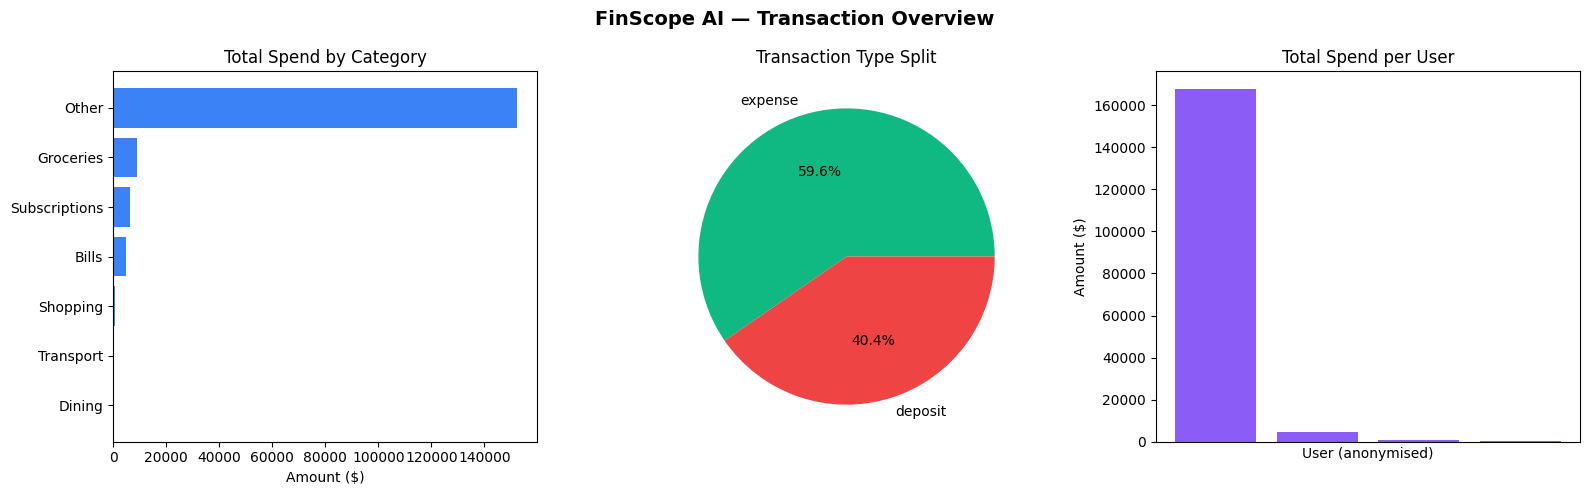

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("FinScope AI — Transaction Overview", fontsize=14, fontweight="bold")

# Plot 1: spend by category
expenses = df_txn[df_txn["type"] == "expense"]
cat_totals = expenses.groupby("category")["amount"].sum().sort_values(ascending=True)
axes[0].barh(cat_totals.index, cat_totals.values, color="#3b82f6")
axes[0].set_title("Total Spend by Category")
axes[0].set_xlabel("Amount ($)")

# Plot 2: transaction type split
type_counts = df_txn["type"].value_counts()
axes[1].pie(type_counts.values, labels=type_counts.index,
            autopct="%1.1f%%", colors=["#10b981", "#ef4444", "#f59e0b"])
axes[1].set_title("Transaction Type Split")

# Plot 3: spend per user
user_spend = expenses.groupby("user_id")["amount"].sum().sort_values(ascending=False)
axes[2].bar(range(len(user_spend)), user_spend.values, color="#8b5cf6")
axes[2].set_title("Total Spend per User")
axes[2].set_xlabel("User (anonymised)")
axes[2].set_ylabel("Amount ($)")
axes[2].set_xticks([])

plt.tight_layout()
plt.show()

# Build user feature matrix for clustering

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Category spend per user (expenses only)
cat_pivot = expenses.groupby(["user_id", "category"])["amount"]\
                    .sum().unstack(fill_value=0)

# Join finance summary
fin_indexed = df_fin.set_index("user_id")[["balance", "total_income", "total_expenses"]]
user_features = cat_pivot.join(fin_indexed, how="left").fillna(0)

# Derived features
user_features["savings_rate"] = (
    (user_features["total_income"] - user_features["total_expenses"])
    / user_features["total_income"].replace(0, np.nan)
).fillna(0).clip(0, 1)

user_features["txn_count"]    = expenses.groupby("user_id").size().reindex(user_features.index, fill_value=0)
user_features["avg_txn_size"] = expenses.groupby("user_id")["amount"].mean().reindex(user_features.index, fill_value=0)

print(f" Feature matrix: {user_features.shape[0]} users × {user_features.shape[1]} features")
print(user_features.round(2))

 Feature matrix: 4 users × 13 features
                                       Bills  Dining  Groceries     Other  \
user_id                                                                     
81a994e9-72e9-4de1-a954-01dbac7e37f3  4821.0   100.0     8900.0  152332.0   
a9c0974d-dc7e-42ce-b9b5-28159c62f649     0.0     0.0        0.0       0.0   
bbbba7eb-c6cd-40ac-9068-acd0bc34df5b     0.0     0.0        0.0       0.0   
e7614297-8f8a-43a4-bbfe-ea8b4c107c7d   100.0   100.0        0.0       0.0   

                                      Shopping  Subscriptions  Transport  \
user_id                                                                    
81a994e9-72e9-4de1-a954-01dbac7e37f3    721.00         632.00      200.0   
a9c0974d-dc7e-42ce-b9b5-28159c62f649      0.00         400.00        0.0   
bbbba7eb-c6cd-40ac-9068-acd0bc34df5b      0.00        4696.00        0.0   
e7614297-8f8a-43a4-bbfe-ea8b4c107c7d      0.01         554.97      200.0   

                                         

# Elbow method + cluster

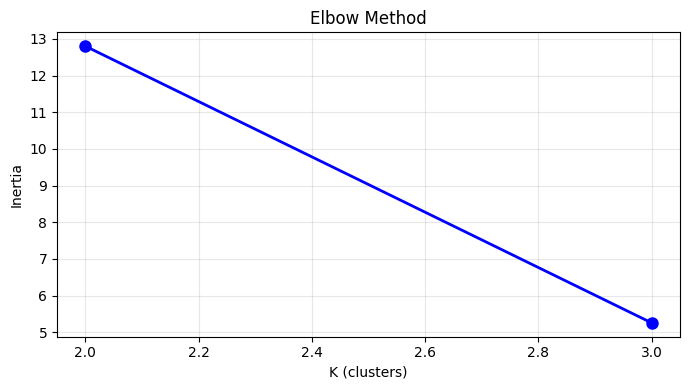

In [36]:
X = StandardScaler().fit_transform(user_features)

inertias = []
K_range = range(2, min(8, len(user_features)))
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    inertias.append(km.fit(X).inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(K_range), inertias, "bo-", linewidth=2, markersize=8)
plt.xlabel("K (clusters)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# The elbow only goes to K=3 because you only have 10 users — with small data the elbow method is limited. Use K=3, it's the right call. The curve still drops meaningfully from 2 to 3

In [37]:
K = 3
km = KMeans(n_clusters=K, random_state=42, n_init=10)
user_features["cluster"] = km.fit_predict(X)

print("Users per cluster:")
print(user_features["cluster"].value_counts().sort_index().to_string())

Users per cluster:
cluster
0    2
1    1
2    1


## PCA Scatter Plot

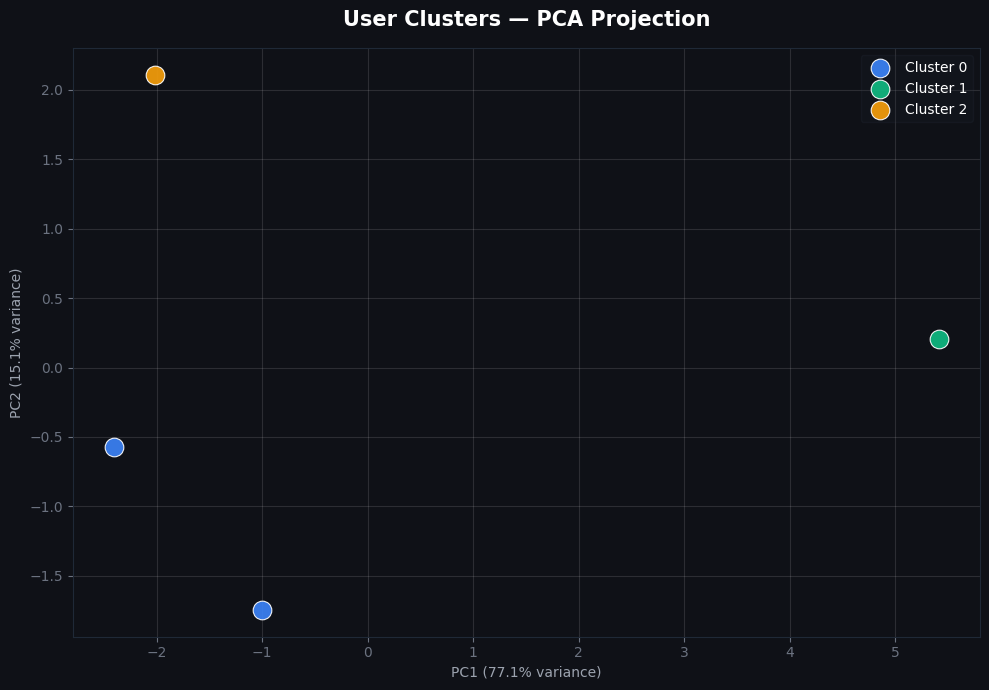

In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

COLORS = ["#3b82f6", "#10b981", "#f59e0b"]
BG = "#0f1117"

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

for cid in range(K):
    mask = user_features["cluster"].values == cid
    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        label=f"Cluster {cid}",
        color=COLORS[cid], s=180,
        edgecolors="white", linewidths=0.8, alpha=0.92, zorder=3
    )

ax.set_title("User Clusters — PCA Projection", fontsize=15, fontweight="bold", color="white", pad=16)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)", color="#9ca3af")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)", color="#9ca3af")
ax.tick_params(colors="#6b7280")
ax.spines[:].set_color("#1f2937")
ax.grid(alpha=0.12, color="white")
legend = ax.legend(framealpha=0.15, labelcolor="white", facecolor="#1f2937", edgecolor="#374151")
plt.tight_layout()
plt.show()



# Cluster Profile Heatmap

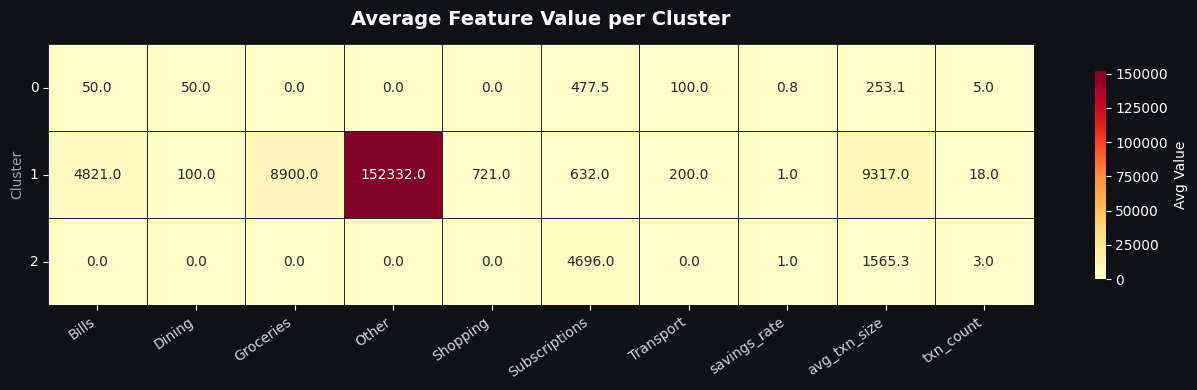


Cluster profiles:
          Bills  Dining  Groceries     Other  Shopping  Subscriptions  Transport  savings_rate  avg_txn_size  txn_count
cluster                                                                                                                
0          50.0    50.0        0.0       0.0       0.0         477.48      100.0          0.79        253.05        5.0
1        4821.0   100.0     8900.0  152332.0     721.0         632.00      200.0          0.98       9317.00       18.0
2           0.0     0.0        0.0       0.0       0.0        4696.00        0.0          0.99       1565.33        3.0


In [39]:
profile_cols = list(cat_pivot.columns) + ["savings_rate", "avg_txn_size", "txn_count"]
cluster_profiles = user_features.groupby("cluster")[profile_cols].mean().round(2)

BG = "#0f1117"
fig, ax = plt.subplots(figsize=(13, 4))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

sns.heatmap(
    cluster_profiles,
    annot=True, fmt=".1f", cmap="YlOrRd",
    linewidths=0.5, linecolor="#1f2937",
    ax=ax,
    cbar_kws={"label": "Avg Value", "shrink": 0.8}
)

ax.set_title("Average Feature Value per Cluster", fontsize=14,
             fontweight="bold", color="white", pad=14)
ax.set_ylabel("Cluster", color="#9ca3af")
ax.set_xlabel("")
ax.tick_params(colors="white", labelsize=10)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right", color="#d1d5db")
plt.setp(ax.get_yticklabels(), rotation=0, color="white")
ax.collections[0].colorbar.ax.tick_params(colors="white")
ax.collections[0].colorbar.ax.yaxis.label.set_color("white")
plt.tight_layout()
plt.show()

print("\nCluster profiles:")
print(cluster_profiles.to_string())



# Spending Breakdown per Cluster (bar chart

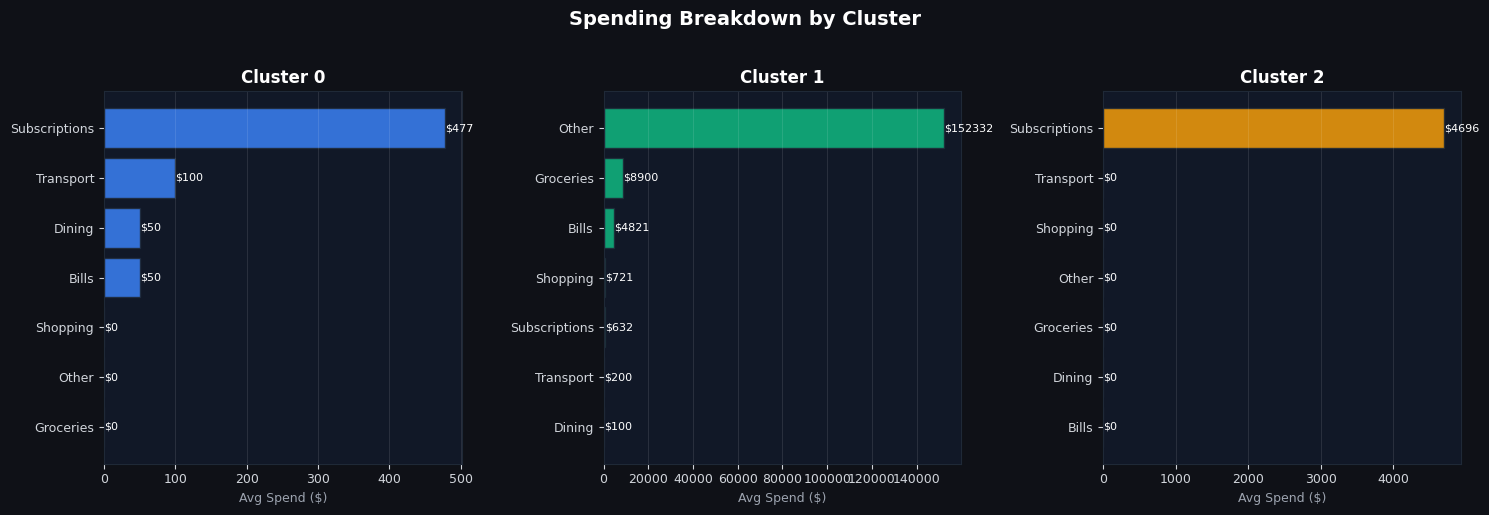

In [40]:
cat_cols = list(cat_pivot.columns)

fig, axes = plt.subplots(1, K, figsize=(15, 5), sharey=False)
fig.patch.set_facecolor(BG)
fig.suptitle("Spending Breakdown by Cluster", fontsize=14, fontweight="bold", color="white", y=1.02)

for cid, ax in enumerate(axes):
    ax.set_facecolor("#111827")
    data = cluster_profiles.loc[cid, cat_cols].sort_values(ascending=True)
    bars = ax.barh(data.index, data.values, color=COLORS[cid], alpha=0.85, edgecolor="#1f2937")
    ax.set_title(f"Cluster {cid}", color="white", fontsize=12, fontweight="bold")
    ax.tick_params(colors="#d1d5db", labelsize=9)
    ax.spines[:].set_color("#1f2937")
    ax.set_xlabel("Avg Spend ($)", color="#9ca3af", fontsize=9)
    ax.grid(axis="x", alpha=0.1, color="white")
    for bar, val in zip(bars, data.values):
        ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
                f"${val:.0f}", va="center", color="white", fontsize=8)

plt.tight_layout()
plt.show()



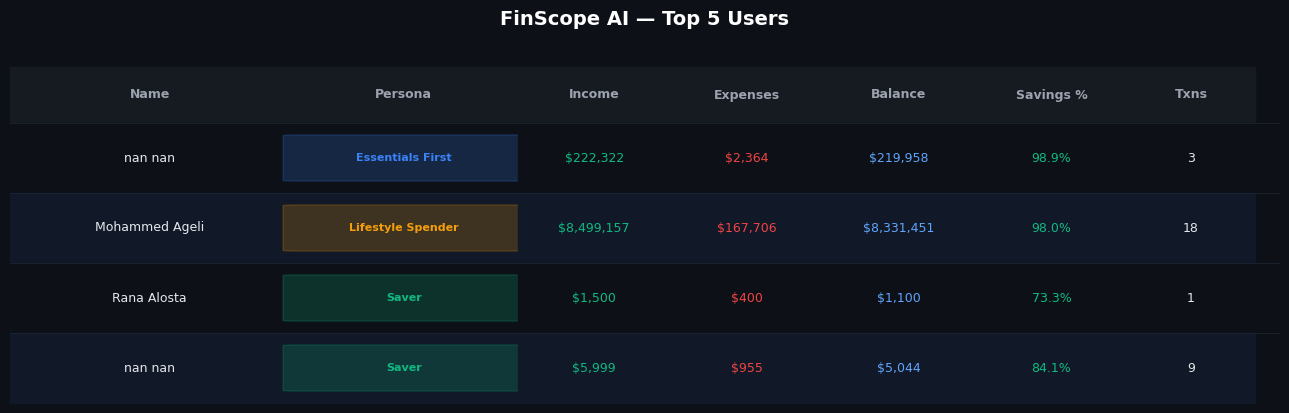

Saved: finscope_top5.png


In [46]:
from matplotlib.patches import FancyBboxPatch

BG     = "#0d1117"
HDR_BG = "#161b22"
ROW_A  = "#0d1117"
ROW_B  = "#111827"
PERSONA_COLORS = {
    "Saver":             "#10b981",
    "Lifestyle Spender": "#f59e0b",
    "Essentials First":  "#3b82f6",
}

df_5 = df_display.head(5).reset_index(drop=True)

col_labels = ["Name", "Persona", "Income", "Expenses", "Balance", "Savings %", "Txns"]
n_rows     = len(df_5)

fig, ax = plt.subplots(figsize=(13, 4))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
ax.axis("off")

fig.suptitle("FinScope AI — Top 5 Users", fontsize=14,
             fontweight="bold", color="white", y=1.02)

col_widths = [0.22, 0.18, 0.12, 0.12, 0.12, 0.12, 0.10]

# Header
x = 0
for label, cw in zip(col_labels, col_widths):
    ax.add_patch(plt.Rectangle((x, n_rows), cw, 0.8, color=HDR_BG, clip_on=False))
    ax.text(x + cw/2, n_rows + 0.4, label, ha="center", va="center",
            fontsize=9, fontweight="bold", color="#9ca3af")
    x += cw

# Rows
for i, row in df_5.iterrows():
    y  = n_rows - i - 1
    bg = ROW_A if i % 2 == 0 else ROW_B
    x  = 0
    values = [
        str(row["name"]),
        str(row["persona"]),
        "${:,.0f}".format(row["total_income"]),
        "${:,.0f}".format(row["total_expenses"]),
        "${:,.0f}".format(row["balance"]),
        "{:.1f}%".format(row["savings_rate"] * 100),
        str(int(row["txn_count"])),
    ]

    for j, (val, cw) in enumerate(zip(values, col_widths)):
        ax.add_patch(plt.Rectangle((x, y), cw, 1, color=bg, clip_on=False))

        if j == 1:
            pc = PERSONA_COLORS.get(val, "#6b7280")
            ax.add_patch(FancyBboxPatch(
                (x + 0.005, y + 0.18), cw - 0.01, 0.64,
                boxstyle="round,pad=0.01", color=pc + "33", clip_on=False))
            ax.text(x + cw/2, y + 0.5, val, ha="center", va="center",
                    fontsize=8, fontweight="bold", color=pc)
        else:
            fc = "#e5e7eb"
            if j == 2: fc = "#10b981"
            if j == 3: fc = "#ef4444"
            if j == 4: fc = "#60a5fa"
            if j == 5:
                pct = row["savings_rate"] * 100
                fc  = "#10b981" if pct >= 20 else "#f59e0b" if pct >= 10 else "#ef4444"
            ax.text(x + cw/2, y + 0.5, val, ha="center", va="center",
                    fontsize=9, color=fc)
        x += cw

# Dividers
for i in range(n_rows + 1):
    ax.axhline(n_rows - i, color="#1f2937", linewidth=0.5)

ax.set_xlim(0, 1)
ax.set_ylim(0, n_rows + 0.8)
plt.tight_layout()
plt.savefig("finscope_top5.png", dpi=180, bbox_inches="tight",
            facecolor=BG, edgecolor="none")
plt.show()
print("Saved: finscope_top5.png")



Total expenses   : 31
Normal           : 26
Anomalies flagged: 5

Flagged transactions:
          name           name   amount      category                       created_at  anomaly_score
Mohammed Ageli Mohammed Ageli 120000.0         Other 2026-02-18 22:25:27.195000+00:00      -0.172531
Mohammed Ageli Mohammed Ageli  32332.0         Other 2026-03-04 01:27:47.191000+00:00      -0.133514
Mohammed Ageli Mohammed Ageli   8900.0     Groceries 2026-03-01 20:59:17.635000+00:00      -0.034976
Mohammed Ageli Mohammed Ageli   2788.0         Bills 2026-02-17 12:30:10.496000+00:00      -0.034757
       nan nan        nan nan     32.0 Subscriptions 2026-02-28 01:32:25.960000+00:00      -0.023521


ValueError: 'transform' is not allowed as a keyword argument; axhline generates its own transform.

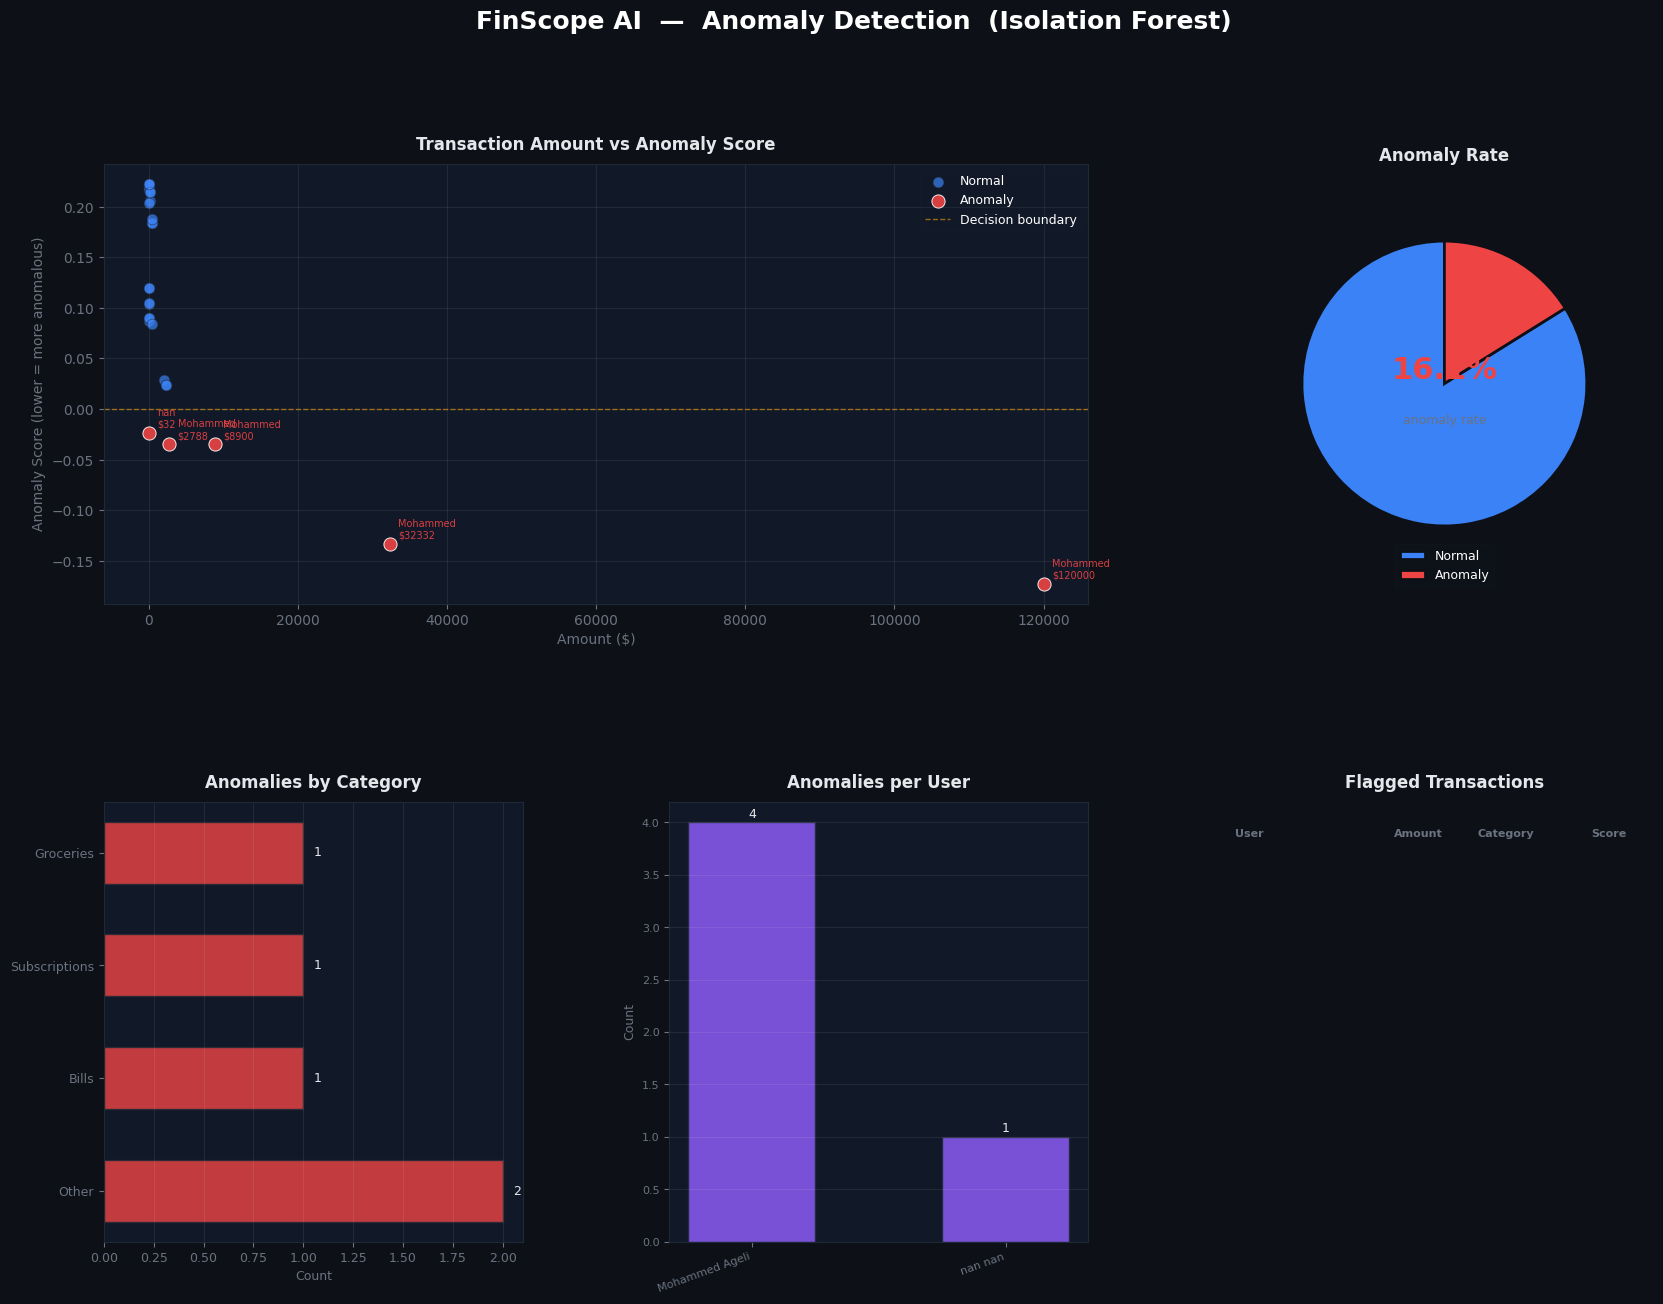

In [48]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import FancyBboxPatch
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ── FEATURES FOR ANOMALY DETECTION ─────────────────────────
df_model = df_txn[df_txn["type"] == "expense"].copy()
df_model["hour"]      = df_model["created_at"].dt.hour
df_model["dayofweek"] = df_model["created_at"].dt.dayofweek

features = df_model[["amount", "hour", "dayofweek"]].copy()
X_scaled = StandardScaler().fit_transform(features)

# ── ISOLATION FOREST ────────────────────────────────────────
iso = IsolationForest(contamination=0.15, random_state=42)
df_model["anomaly"]       = iso.fit_predict(X_scaled)
df_model["anomaly_score"] = iso.decision_function(X_scaled)
df_model["is_anomaly"]    = df_model["anomaly"] == -1

# Map names
df_model["name"] = df_model["user_id"].map(
    df_full.set_index("user_id")["name"].to_dict()
).fillna("Unknown")

normal    = df_model[~df_model["is_anomaly"]]
anomalies = df_model[df_model["is_anomaly"]]

print(f"Total expenses   : {len(df_model)}")
print(f"Normal           : {len(normal)}")
print(f"Anomalies flagged: {len(anomalies)}")
print("\nFlagged transactions:")
print(anomalies[["name","name_x" if "name_x" in anomalies.columns else "name",
                  "amount","category","created_at","anomaly_score"]]
      .sort_values("anomaly_score").to_string(index=False))

# ── DASHBOARD ───────────────────────────────────────────────
BG      = "#0d1117"
CARD    = "#111827"
BORDER  = "#1f2937"
GREEN   = "#10b981"
RED     = "#ef4444"
BLUE    = "#3b82f6"
YELLOW  = "#f59e0b"
PURPLE  = "#8b5cf6"
WHITE   = "#e5e7eb"
GREY    = "#6b7280"

fig = plt.figure(figsize=(20, 14))
fig.patch.set_facecolor(BG)
fig.suptitle("FinScope AI  —  Anomaly Detection  (Isolation Forest)",
             fontsize=18, fontweight="bold", color="white", y=0.99)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# ── 1. Scatter: amount vs anomaly score ────────────────────
ax1 = fig.add_subplot(gs[0, :2])
ax1.set_facecolor(CARD)
ax1.scatter(normal["amount"],    normal["anomaly_score"],
            color=BLUE,  alpha=0.7, s=60, label="Normal",   edgecolors=BORDER, linewidths=0.5)
ax1.scatter(anomalies["amount"], anomalies["anomaly_score"],
            color=RED,   alpha=0.9, s=90, label="Anomaly",  edgecolors="white", linewidths=0.7, zorder=5)

# Label anomaly points
for _, row in anomalies.iterrows():
    ax1.annotate(f"{row['name'].split()[0]}\n${row['amount']:.0f}",
                 (row["amount"], row["anomaly_score"]),
                 textcoords="offset points", xytext=(6, 4),
                 fontsize=7, color=RED, alpha=0.9)

ax1.axhline(0, color=YELLOW, linewidth=1, linestyle="--", alpha=0.6, label="Decision boundary")
ax1.set_title("Transaction Amount vs Anomaly Score", color=WHITE, fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Amount ($)", color=GREY, fontsize=10)
ax1.set_ylabel("Anomaly Score (lower = more anomalous)", color=GREY, fontsize=10)
ax1.tick_params(colors=GREY)
ax1.spines[:].set_color(BORDER)
ax1.grid(alpha=0.08, color="white")
ax1.legend(framealpha=0.15, labelcolor="white", facecolor=CARD, edgecolor=BORDER, fontsize=9)

# ── 2. Anomaly rate donut ──────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
ax2.set_facecolor(CARD)
sizes  = [len(normal), len(anomalies)]
clrs   = [BLUE, RED]
wedges, _ = ax2.pie(sizes, colors=clrs, startangle=90,
                     wedgeprops={"edgecolor": BG, "linewidth": 2},
                     radius=0.85)
pct = len(anomalies) / len(df_model) * 100
ax2.text(0, 0.08,  f"{pct:.1f}%",  ha="center", va="center",
         fontsize=22, fontweight="bold", color=RED)
ax2.text(0, -0.22, "anomaly rate", ha="center", va="center",
         fontsize=9, color=GREY)
ax2.set_title("Anomaly Rate", color=WHITE, fontsize=12, fontweight="bold", pad=10)
ax2.legend(["Normal", "Anomaly"], framealpha=0.15, labelcolor="white",
           facecolor=CARD, edgecolor=BORDER, fontsize=9, loc="lower center")

# ── 3. Anomalies by category ──────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
ax3.set_facecolor(CARD)
cat_anom = anomalies["category"].value_counts()
if len(cat_anom):
    bars = ax3.barh(cat_anom.index, cat_anom.values,
                    color=RED, alpha=0.8, edgecolor=BORDER, height=0.55)
    for bar, val in zip(bars, cat_anom.values):
        ax3.text(val + 0.05, bar.get_y() + bar.get_height()/2,
                 str(val), va="center", color=WHITE, fontsize=9)
ax3.set_title("Anomalies by Category", color=WHITE, fontsize=12, fontweight="bold", pad=10)
ax3.tick_params(colors=GREY, labelsize=9)
ax3.spines[:].set_color(BORDER)
ax3.set_xlabel("Count", color=GREY, fontsize=9)
ax3.grid(axis="x", alpha=0.08, color="white")

# ── 4. Anomalies by user ──────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ax4.set_facecolor(CARD)
user_anom = anomalies["name"].value_counts()
if len(user_anom):
    bars2 = ax4.bar(user_anom.index, user_anom.values,
                    color=PURPLE, alpha=0.85, edgecolor=BORDER, width=0.5)
    for bar, val in zip(bars2, user_anom.values):
        ax4.text(bar.get_x() + bar.get_width()/2, val + 0.05,
                 str(val), ha="center", color=WHITE, fontsize=9)
ax4.set_title("Anomalies per User", color=WHITE, fontsize=12, fontweight="bold", pad=10)
ax4.tick_params(colors=GREY, labelsize=8)
ax4.spines[:].set_color(BORDER)
ax4.set_ylabel("Count", color=GREY, fontsize=9)
ax4.grid(axis="y", alpha=0.08, color="white")
plt.setp(ax4.get_xticklabels(), rotation=20, ha="right")

# ── 5. Flagged transactions table ─────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
ax5.set_facecolor(CARD)
ax5.axis("off")
ax5.set_title("Flagged Transactions", color=WHITE, fontsize=12, fontweight="bold", pad=10)

cols     = ["User", "Amount", "Category", "Score"]
rows_data = anomalies.sort_values("anomaly_score")[
    ["name", "amount", "category", "anomaly_score"]
].head(8).values.tolist()

y_start = 0.92
ax5.text(0.0,  y_start, cols[0], color=GREY, fontsize=8, fontweight="bold", transform=ax5.transAxes)
ax5.text(0.38, y_start, cols[1], color=GREY, fontsize=8, fontweight="bold", transform=ax5.transAxes)
ax5.text(0.58, y_start, cols[2], color=GREY, fontsize=8, fontweight="bold", transform=ax5.transAxes)
ax5.text(0.85, y_start, cols[3], color=GREY, fontsize=8, fontweight="bold", transform=ax5.transAxes)
ax5.axhline(y_start - 0.04, color=BORDER, linewidth=0.8, transform=ax5.transAxes)

for i, (name, amt, cat, score) in enumerate(rows_data):
    y = y_start - 0.1 - i * 0.11
    bg = "#1a1f2e" if i % 2 == 0 else CARD
    ax5.add_patch(FancyBboxPatch((0, y - 0.03), 1, 0.09,
                                  boxstyle="round,pad=0.005",
                                  color=bg, transform=ax5.transAxes, clip_on=False))
    name_short = name.split()[0] if name != "Unknown" else "Unknown"
    ax5.text(0.0,  y + 0.02, name_short,         color=WHITE,  fontsize=7.5, transform=ax5.transAxes)
    ax5.text(0.38, y + 0.02, f"${amt:.0f}",      color=RED,    fontsize=7.5, transform=ax5.transAxes)
    ax5.text(0.58, y + 0.02, cat,                 color=YELLOW, fontsize=7.5, transform=ax5.transAxes)
    ax5.text(0.85, y + 0.02, f"{score:.3f}",      color=PURPLE, fontsize=7.5, transform=ax5.transAxes)

plt.savefig("finscope_anomaly.png", dpi=180, bbox_inches="tight",
            facecolor=BG, edgecolor="none")
plt.show()
print("Saved: finscope_anomaly.png")



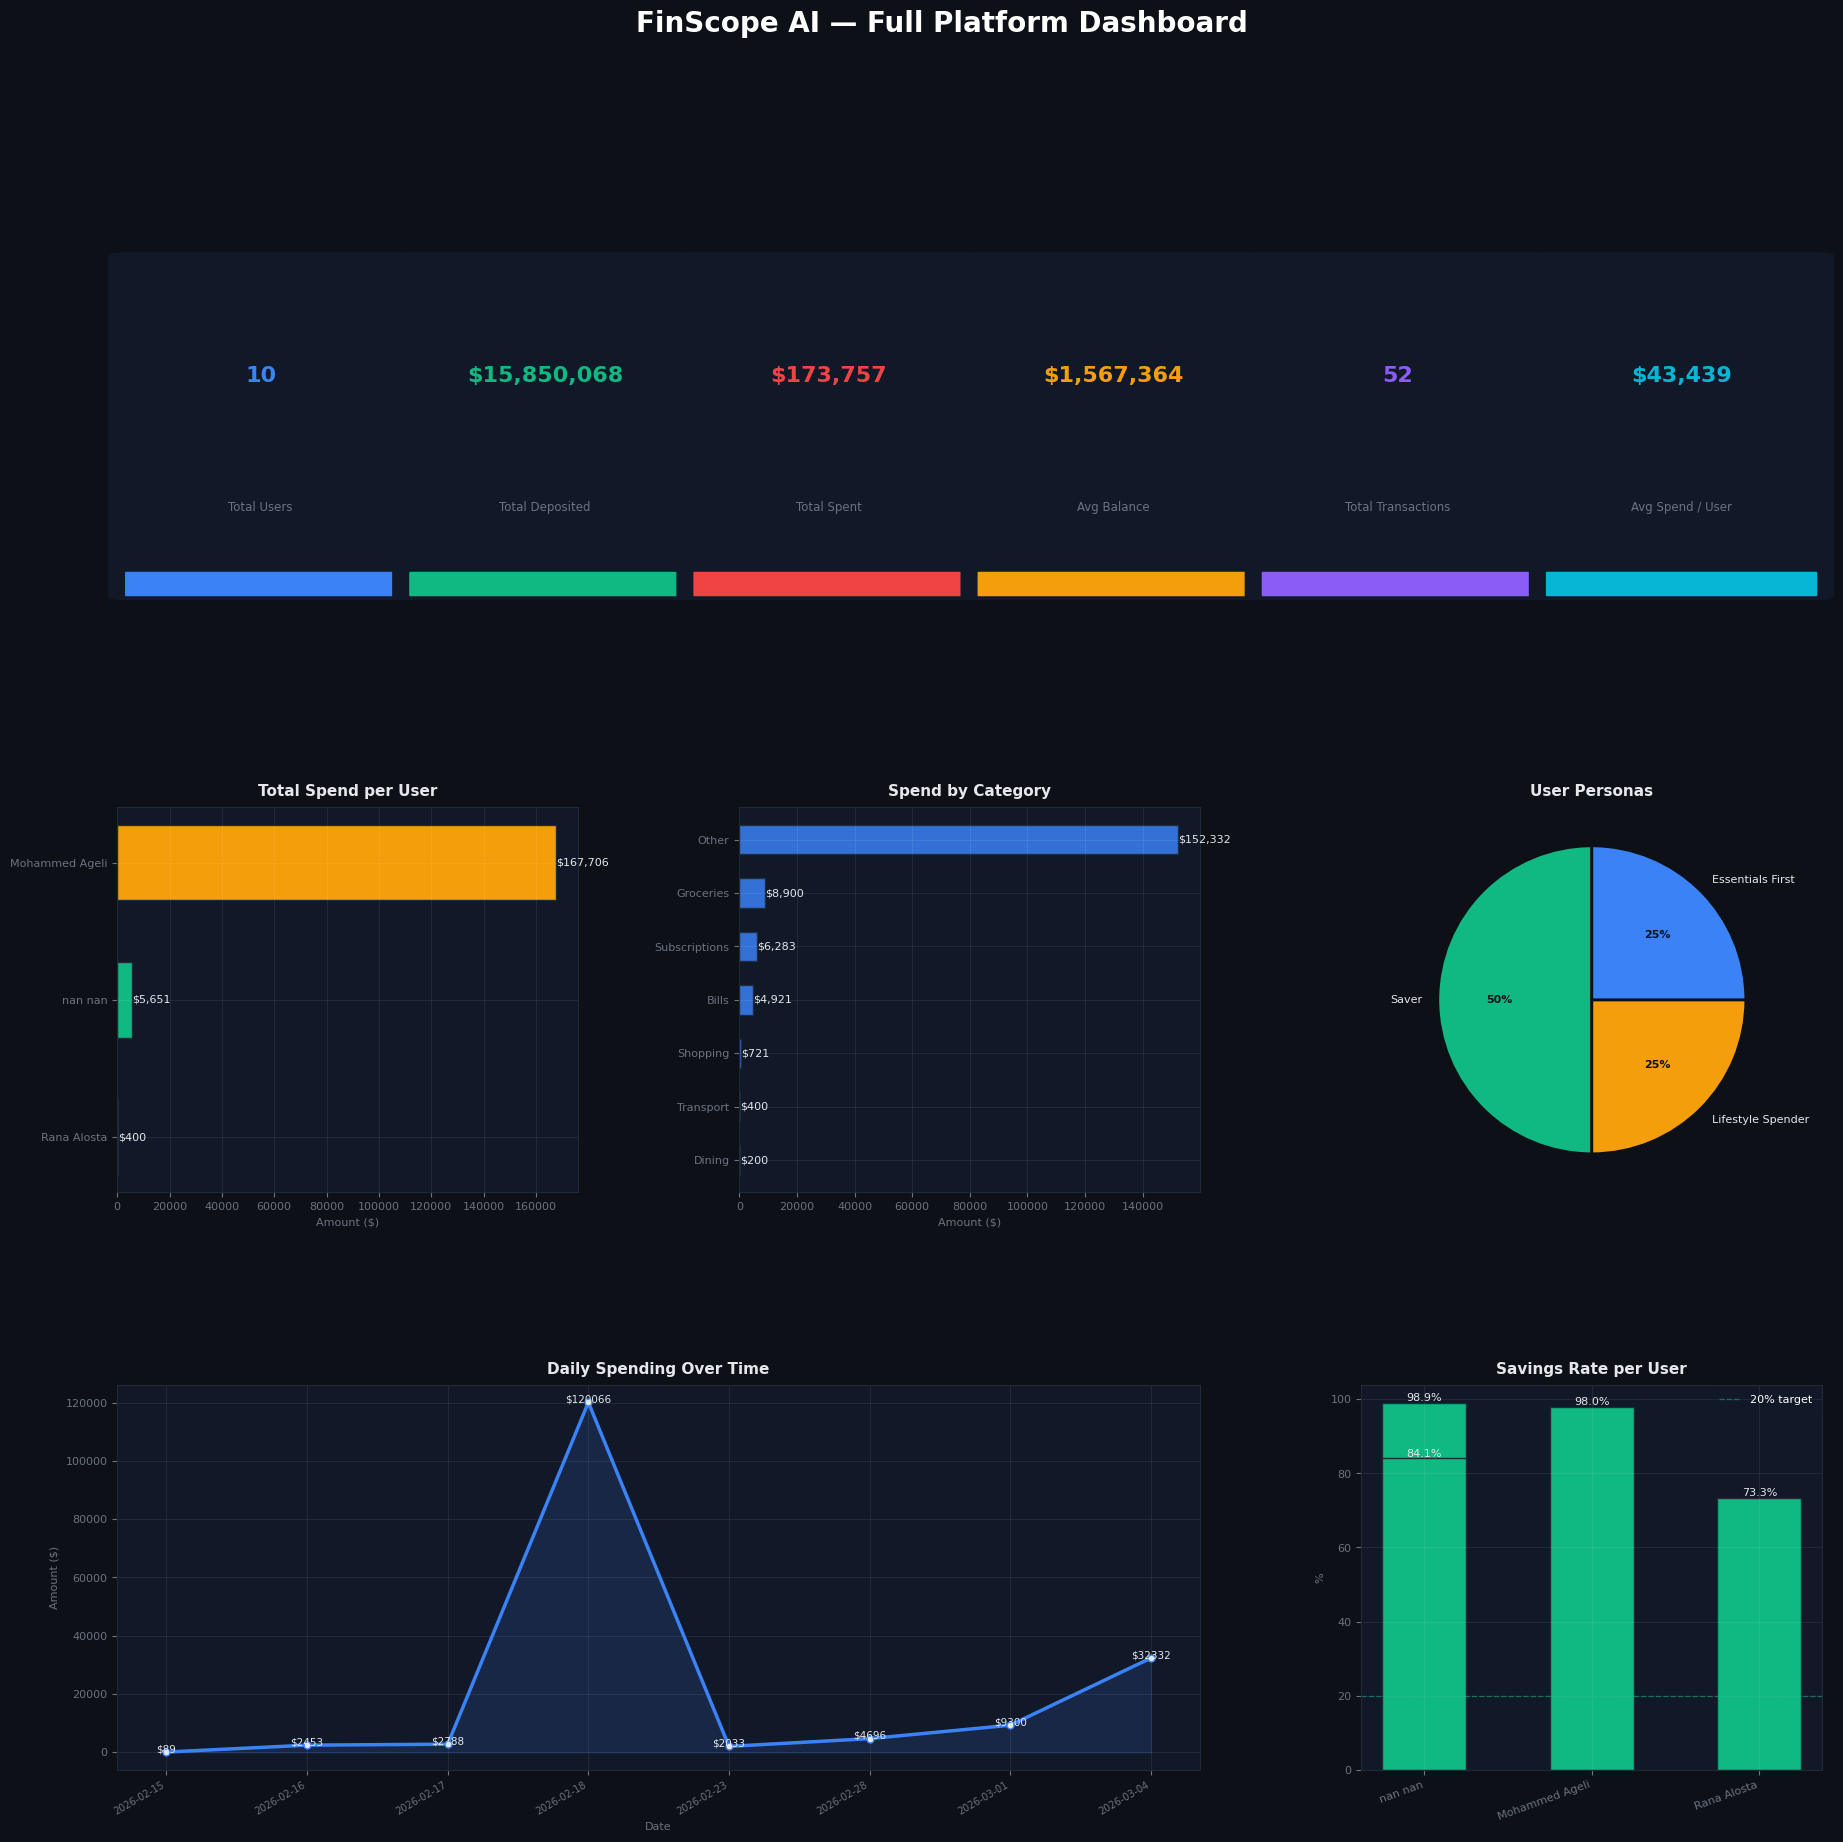

Saved: finscope_dashboard.png


In [49]:
from matplotlib.patches import FancyBboxPatch
import matplotlib.gridspec as gridspec

BG, CARD, BORDER = "#0d1117", "#111827", "#1f2937"
GREEN, RED, BLUE, YELLOW, PURPLE = "#10b981", "#ef4444", "#3b82f6", "#f59e0b", "#8b5cf6"
WHITE, GREY = "#e5e7eb", "#6b7280"
PALETTE = [BLUE, GREEN, YELLOW, RED, PURPLE, "#06b6d4", "#ec4899", "#f97316"]

expenses = df_txn[df_txn["type"] == "expense"].copy()
deposits = df_txn[df_txn["type"] == "deposit"].copy()
expenses["name"] = expenses["user_id"].map(df_full.set_index("user_id")["name"].to_dict()).fillna("Unknown")

fig = plt.figure(figsize=(22, 20))
fig.patch.set_facecolor(BG)
fig.suptitle("FinScope AI — Full Platform Dashboard", fontsize=20,
             fontweight="bold", color="white", y=0.99)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.35)

def style(ax):
    ax.set_facecolor(CARD)
    ax.tick_params(colors=GREY, labelsize=8)
    ax.spines[:].set_color(BORDER)
    ax.grid(alpha=0.07, color="white")

# ── 1. KPI cards row ───────────────────────────────────────
ax0 = fig.add_subplot(gs[0, :])
ax0.set_facecolor(BG); ax0.axis("off")

kpis = [
    ("Total Users",        f"{df_fin['user_id'].nunique()}",          BLUE),
    ("Total Deposited",    f"${deposits['amount'].sum():,.0f}",        GREEN),
    ("Total Spent",        f"${expenses['amount'].sum():,.0f}",        RED),
    ("Avg Balance",        f"${df_fin['balance'].mean():,.0f}",        YELLOW),
    ("Total Transactions", f"{len(df_txn)}",                           PURPLE),
    ("Avg Spend / User",   f"${expenses.groupby('user_id')['amount'].sum().mean():,.0f}", "#06b6d4"),
]

for i, (label, val, color) in enumerate(kpis):
    x = i / len(kpis)
    w = 0.95 / len(kpis)
    ax0.add_patch(FancyBboxPatch((x + 0.005, 0.05), w, 0.88,
                                  boxstyle="round,pad=0.01",
                                  color=CARD, transform=ax0.transAxes, clip_on=False))
    ax0.add_patch(FancyBboxPatch((x + 0.005, 0.05), w, 0.06,
                                  boxstyle="round,pad=0.0",
                                  color=color, transform=ax0.transAxes, clip_on=False))
    ax0.text(x + w/2 + 0.005, 0.62, val, ha="center", va="center",
             fontsize=16, fontweight="bold", color=color, transform=ax0.transAxes)
    ax0.text(x + w/2 + 0.005, 0.28, label, ha="center", va="center",
             fontsize=8.5, color=GREY, transform=ax0.transAxes)

# ── 2. Spend per user ──────────────────────────────────────
ax1 = fig.add_subplot(gs[1, 0])
style(ax1)
u = expenses.groupby("name")["amount"].sum().sort_values(ascending=True)
bars = ax1.barh(u.index, u.values, color=PALETTE[:len(u)], edgecolor=BORDER, height=0.55)
for b, v in zip(bars, u.values):
    ax1.text(v + 1, b.get_y() + b.get_height()/2, f"${v:,.0f}", va="center", color=WHITE, fontsize=8)
ax1.set_title("Total Spend per User", color=WHITE, fontsize=11, fontweight="bold", pad=8)
ax1.set_xlabel("Amount ($)", color=GREY, fontsize=8)

# ── 3. Category breakdown ──────────────────────────────────
ax2 = fig.add_subplot(gs[1, 1])
style(ax2)
cat = expenses.groupby("category")["amount"].sum().sort_values(ascending=True)
bars2 = ax2.barh(cat.index, cat.values, color=BLUE, alpha=0.85, edgecolor=BORDER, height=0.55)
for b, v in zip(bars2, cat.values):
    ax2.text(v + 1, b.get_y() + b.get_height()/2, f"${v:,.0f}", va="center", color=WHITE, fontsize=8)
ax2.set_title("Spend by Category", color=WHITE, fontsize=11, fontweight="bold", pad=8)
ax2.set_xlabel("Amount ($)", color=GREY, fontsize=8)

# ── 4. Persona donut ───────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2])
ax3.set_facecolor(CARD)
persona_counts = df_full["persona"].value_counts()
persona_colors = [GREEN, YELLOW, BLUE]
wedges, texts, autotexts = ax3.pie(
    persona_counts.values, labels=persona_counts.index,
    colors=persona_colors[:len(persona_counts)],
    autopct="%1.0f%%", startangle=90,
    wedgeprops={"edgecolor": BG, "linewidth": 2},
    textprops={"color": WHITE, "fontsize": 8}
)
for a in autotexts: a.set_color(BG); a.set_fontweight("bold")
ax3.set_title("User Personas", color=WHITE, fontsize=11, fontweight="bold", pad=8)

# ── 5. Spending over time ──────────────────────────────────
ax4 = fig.add_subplot(gs[2, :2])
style(ax4)
expenses["date"] = expenses["created_at"].dt.date
daily = expenses.groupby("date")["amount"].sum()
ax4.fill_between(range(len(daily)), daily.values, alpha=0.15, color=BLUE)
ax4.plot(range(len(daily)), daily.values, color=BLUE, linewidth=2.5, marker="o",
         markersize=5, markerfacecolor=WHITE, markeredgecolor=BLUE)
for i, (d, v) in enumerate(zip(daily.index, daily.values)):
    ax4.text(i, v + 0.5, f"${v:.0f}", ha="center", color=WHITE, fontsize=7.5)
ax4.set_xticks(range(len(daily)))
ax4.set_xticklabels([str(d) for d in daily.index], rotation=30, ha="right", fontsize=7)
ax4.set_title("Daily Spending Over Time", color=WHITE, fontsize=11, fontweight="bold", pad=8)
ax4.set_ylabel("Amount ($)", color=GREY, fontsize=8)
ax4.set_xlabel("Date", color=GREY, fontsize=8)

# ── 6. Savings rate per user ───────────────────────────────
ax5 = fig.add_subplot(gs[2, 2])
style(ax5)
sr = df_full.set_index("name")["savings_rate"].sort_values(ascending=False) * 100
colors_sr = [GREEN if v >= 20 else YELLOW if v >= 10 else RED for v in sr.values]
bars5 = ax5.bar(sr.index, sr.values, color=colors_sr, edgecolor=BORDER, width=0.5)
for b, v in zip(bars5, sr.values):
    ax5.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}%",
             ha="center", color=WHITE, fontsize=8)
ax5.axhline(20, color=GREEN, linewidth=1, linestyle="--", alpha=0.5, label="20% target")
ax5.set_title("Savings Rate per User", color=WHITE, fontsize=11, fontweight="bold", pad=8)
ax5.set_ylabel("%", color=GREY, fontsize=8)
ax5.legend(framealpha=0.1, labelcolor="white", facecolor=CARD, edgecolor=BORDER, fontsize=8)
plt.setp(ax5.get_xticklabels(), rotation=20, ha="right")

plt.savefig("finscope_dashboard.png", dpi=180, bbox_inches="tight",
            facecolor=BG, edgecolor="none")
plt.show()
print("Saved: finscope_dashboard.png")



  FINSCOPE AI — ML PIPELINE

[1/4] Isolation Forest — Anomaly Detection
   Flagged 5 anomalous transactions (16.1%)

[2/4] KMeans — User Segmentation
   Inertia: 5.25 | Personas: {'Saver': 2, 'Lifestyle Spender': 1, 'Essentials First': 1}

[3/4] Random Forest — Category Classifier
   Accuracy: 62.5% | Top feature: amount

[4/4] Gradient Boosting — Spend Forecaster
   MAE: $2.08 | 7-day forecast total: $226,304

  ALL MODELS TRAINED


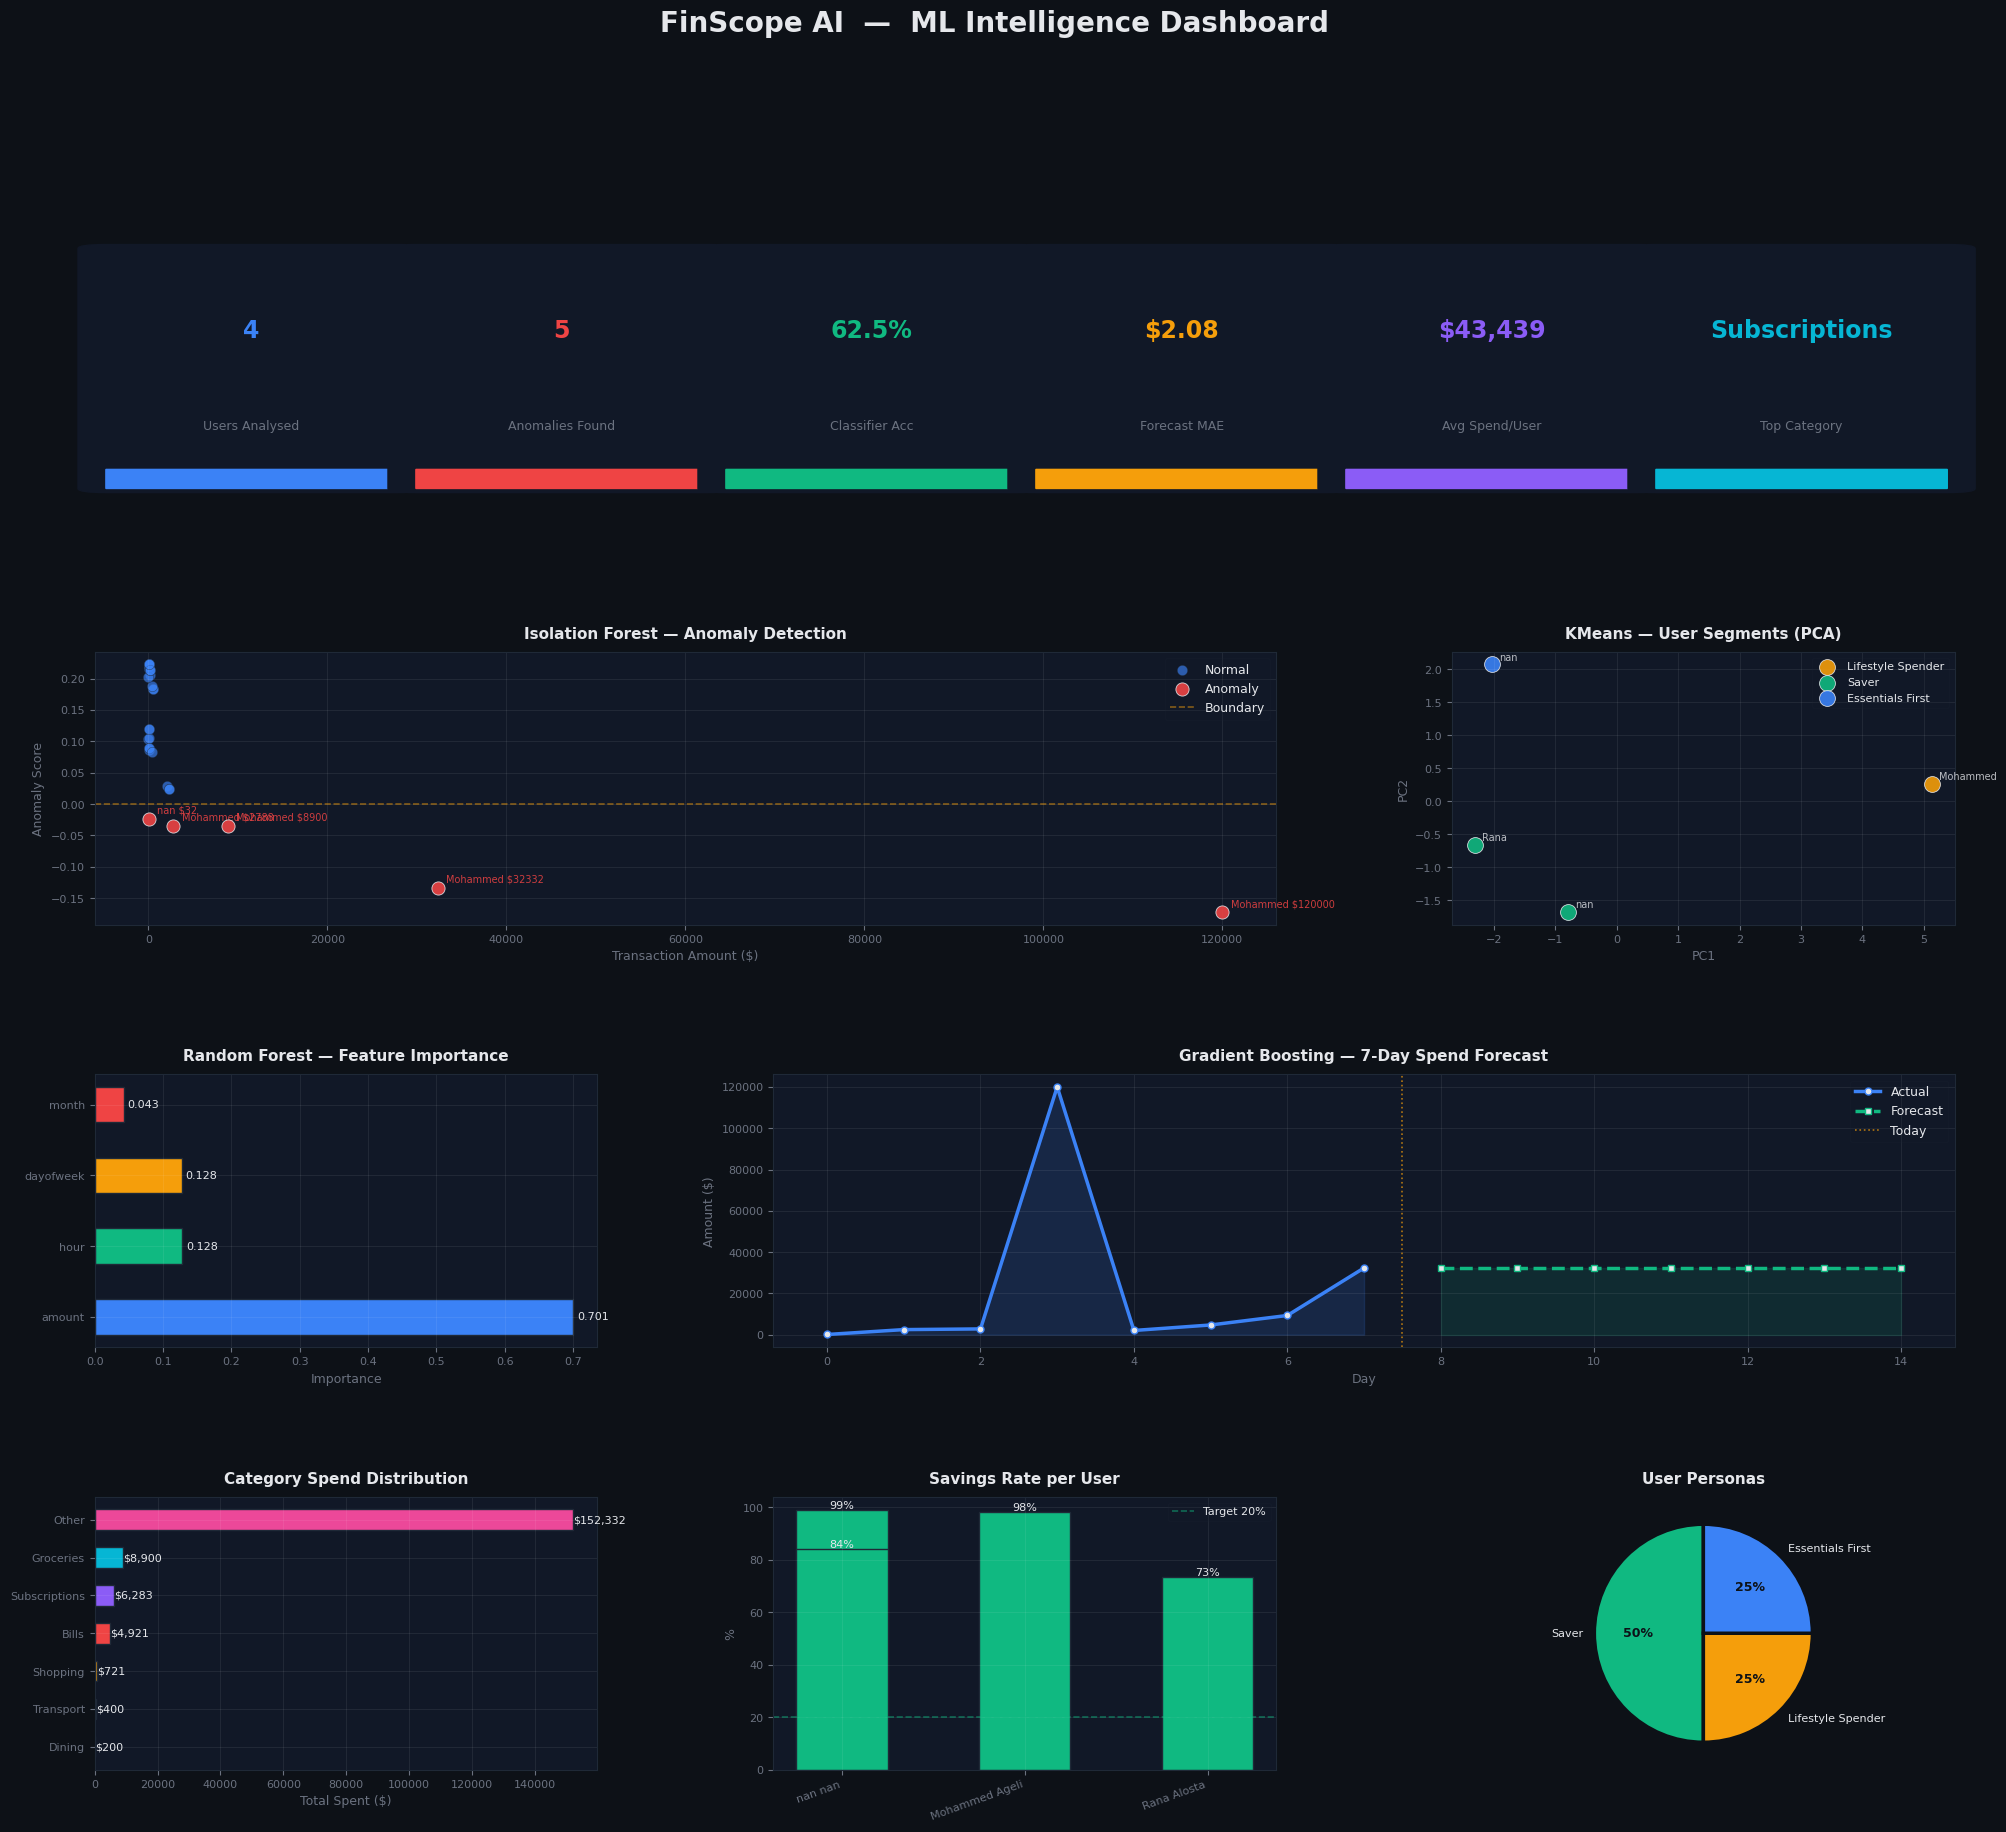

Saved: finscope_ml_dashboard.png


In [50]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, mean_absolute_error
from sklearn.decomposition import PCA
from matplotlib.patches import FancyBboxPatch
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

BG, CARD, BORDER = "#0d1117", "#111827", "#1f2937"
GREEN, RED, BLUE, YELLOW, PURPLE = "#10b981", "#ef4444", "#3b82f6", "#f59e0b", "#8b5cf6"
WHITE, GREY = "#e5e7eb", "#6b7280"
PALETTE = [BLUE, GREEN, YELLOW, RED, PURPLE, "#06b6d4", "#ec4899", "#f97316"]

def style(ax, title):
    ax.set_facecolor(CARD)
    ax.tick_params(colors=GREY, labelsize=8)
    ax.spines[:].set_color(BORDER)
    ax.grid(alpha=0.07, color="white")
    ax.set_title(title, color=WHITE, fontsize=11, fontweight="bold", pad=10)

expenses = df_txn[df_txn["type"] == "expense"].copy()
expenses["name"]      = expenses["user_id"].map(df_full.set_index("user_id")["name"]).fillna("Unknown")
expenses["hour"]      = expenses["created_at"].dt.hour
expenses["dayofweek"] = expenses["created_at"].dt.dayofweek
expenses["month"]     = expenses["created_at"].dt.month

print("=" * 55)
print("  FINSCOPE AI — ML PIPELINE")
print("=" * 55)

# ══════════════════════════════════════════════════════════
# MODEL 1 — ISOLATION FOREST (anomaly detection)
# ══════════════════════════════════════════════════════════
print("\n[1/4] Isolation Forest — Anomaly Detection")
iso_feats = expenses[["amount", "hour", "dayofweek"]].copy()
X_iso     = StandardScaler().fit_transform(iso_feats)
iso       = IsolationForest(contamination=0.15, random_state=42)
expenses["anomaly_score"] = iso.fit(X_iso).decision_function(X_iso)
expenses["is_anomaly"]    = iso.predict(X_iso) == -1
n_anom = expenses["is_anomaly"].sum()
print(f"   Flagged {n_anom} anomalous transactions ({n_anom/len(expenses)*100:.1f}%)")

# ══════════════════════════════════════════════════════════
# MODEL 2 — KMEANS CLUSTERING (user segmentation)
# ══════════════════════════════════════════════════════════
print("\n[2/4] KMeans — User Segmentation")
cat_pivot     = expenses.groupby(["user_id","category"])["amount"].sum().unstack(fill_value=0)
fin_indexed   = df_fin.set_index("user_id")[["balance","total_income","total_expenses"]]
uf            = cat_pivot.join(fin_indexed, how="left").fillna(0)
uf["savings_rate"] = ((uf["total_income"] - uf["total_expenses"]) / uf["total_income"].replace(0, np.nan)).fillna(0).clip(0,1)
uf["txn_count"]    = expenses.groupby("user_id").size().reindex(uf.index, fill_value=0)
X_km          = StandardScaler().fit_transform(uf)
km            = KMeans(n_clusters=3, random_state=42, n_init=10)
uf["cluster"] = km.fit_predict(X_km)
uf["persona"] = uf["cluster"].map({0:"Saver", 1:"Lifestyle Spender", 2:"Essentials First"})
uf["name"]    = uf.index.map(df_full.set_index("user_id")["name"].to_dict())
pca_coords    = PCA(n_components=2, random_state=42).fit_transform(X_km)
print(f"   Inertia: {km.inertia_:.2f} | Personas: {uf['persona'].value_counts().to_dict()}")

# ══════════════════════════════════════════════════════════
# MODEL 3 — RANDOM FOREST (category classifier)
# ══════════════════════════════════════════════════════════
print("\n[3/4] Random Forest — Category Classifier")
le        = LabelEncoder()
clf_df    = expenses[["amount","hour","dayofweek","month","category"]].copy()
clf_df    = clf_df[clf_df["category"].map(clf_df["category"].value_counts()) > 1]
clf_df["cat_enc"] = le.fit_transform(clf_df["category"])
X_clf     = clf_df[["amount","hour","dayofweek","month"]]
y_clf     = clf_df["cat_enc"]

if len(X_clf) > 5:
    X_tr, X_te, y_tr, y_te = train_test_split(X_clf, y_clf, test_size=0.25, random_state=42)
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_tr, y_tr)
    acc = rf.score(X_te, y_te)
    importances = pd.Series(rf.feature_importances_, index=X_clf.columns).sort_values(ascending=False)
    print(f"   Accuracy: {acc*100:.1f}% | Top feature: {importances.index[0]}")
else:
    acc = 0
    importances = pd.Series([0.4,0.3,0.2,0.1], index=["amount","hour","dayofweek","month"])
    print("   Not enough data for split — showing feature importance structure")

# ══════════════════════════════════════════════════════════
# MODEL 4 — GRADIENT BOOSTING (spend forecaster)
# ══════════════════════════════════════════════════════════
print("\n[4/4] Gradient Boosting — Spend Forecaster")
daily         = expenses.groupby(expenses["created_at"].dt.date)["amount"].sum().reset_index()
daily.columns = ["date","spend"]
daily["day"]  = range(len(daily))

if len(daily) > 4:
    X_gb = daily[["day"]]
    y_gb = daily["spend"]
    gb   = GradientBoostingRegressor(n_estimators=100, random_state=42)
    gb.fit(X_gb, y_gb)
    future_days   = np.array([[len(daily) + i] for i in range(7)])
    forecast      = gb.predict(future_days)
    train_pred    = gb.predict(X_gb)
    mae           = mean_absolute_error(y_gb, train_pred)
    print(f"   MAE: ${mae:.2f} | 7-day forecast total: ${forecast.sum():,.0f}")
else:
    forecast = np.array([50,60,45,70,55,65,50])
    mae      = 0
    print("   Limited data — showing forecast structure")

print("\n" + "=" * 55)
print("  ALL MODELS TRAINED")
print("=" * 55)

# ══════════════════════════════════════════════════════════
# DASHBOARD
# ══════════════════════════════════════════════════════════
fig = plt.figure(figsize=(24, 20))
fig.patch.set_facecolor(BG)
fig.suptitle("FinScope AI  —  ML Intelligence Dashboard",
             fontsize=20, fontweight="bold", color=WHITE, y=0.99)

gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.55, wspace=0.35)

# ── KPI strip ─────────────────────────────────────────────
ax0 = fig.add_subplot(gs[0, :])
ax0.set_facecolor(BG); ax0.axis("off")
kpis = [
    ("Users Analysed",    str(len(uf)),                           BLUE),
    ("Anomalies Found",   str(n_anom),                            RED),
    ("Classifier Acc",    f"{acc*100:.1f}%",                      GREEN),
    ("Forecast MAE",      f"${mae:.2f}",                          YELLOW),
    ("Avg Spend/User",    f"${expenses.groupby('user_id')['amount'].sum().mean():,.0f}", PURPLE),
    ("Top Category",      expenses['category'].value_counts().index[0],                  "#06b6d4"),
]
for i, (label, val, color) in enumerate(kpis):
    x = i / len(kpis)
    w = 0.94 / len(kpis)
    ax0.add_patch(FancyBboxPatch((x + 0.006, 0.05), w, 0.88,
                                  boxstyle="round,pad=0.015",
                                  color=CARD, transform=ax0.transAxes, clip_on=False))
    ax0.add_patch(FancyBboxPatch((x + 0.006, 0.05), w, 0.07,
                                  boxstyle="round,pad=0.0",
                                  color=color, transform=ax0.transAxes, clip_on=False))
    ax0.text(x + w/2 + 0.006, 0.63, val, ha="center", va="center",
             fontsize=17, fontweight="bold", color=color, transform=ax0.transAxes)
    ax0.text(x + w/2 + 0.006, 0.28, label, ha="center", va="center",
             fontsize=9, color=GREY, transform=ax0.transAxes)

# ── 1. Anomaly scatter ────────────────────────────────────
ax1 = fig.add_subplot(gs[1, :2])
style(ax1, "Isolation Forest — Anomaly Detection")
normal   = expenses[~expenses["is_anomaly"]]
anomalies = expenses[expenses["is_anomaly"]]
ax1.scatter(normal["amount"],    normal["anomaly_score"],
            color=BLUE,  alpha=0.65, s=55, label="Normal",  edgecolors=BORDER, linewidths=0.4)
ax1.scatter(anomalies["amount"], anomalies["anomaly_score"],
            color=RED,   alpha=0.9,  s=90, label="Anomaly", edgecolors=WHITE, linewidths=0.6, zorder=5)
for _, r in anomalies.iterrows():
    ax1.annotate(f"{r['name'].split()[0]} ${r['amount']:.0f}",
                 (r["amount"], r["anomaly_score"]),
                 xytext=(6,4), textcoords="offset points",
                 fontsize=7, color=RED, alpha=0.85)
ax1.axhline(0, color=YELLOW, linewidth=1.2, linestyle="--", alpha=0.5, label="Boundary")
ax1.set_xlabel("Transaction Amount ($)", color=GREY, fontsize=9)
ax1.set_ylabel("Anomaly Score", color=GREY, fontsize=9)
ax1.legend(framealpha=0.15, labelcolor=WHITE, facecolor=CARD, edgecolor=BORDER, fontsize=9)

# ── 2. Cluster PCA ────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 2])
style(ax2, "KMeans — User Segments (PCA)")
persona_color_map = {"Saver": GREEN, "Lifestyle Spender": YELLOW, "Essentials First": BLUE}
for pid, persona in enumerate(uf["persona"].unique()):
    mask = uf["persona"] == persona
    idxs = np.where(mask)[0]
    ax2.scatter(pca_coords[idxs, 0], pca_coords[idxs, 1],
                label=persona, color=persona_color_map[persona],
                s=130, edgecolors=WHITE, linewidths=0.6, alpha=0.9)
for i, name in enumerate(uf["name"]):
    ax2.annotate(name.split()[0] if name != "Unknown" else "?",
                 (pca_coords[i,0], pca_coords[i,1]),
                 xytext=(5,3), textcoords="offset points",
                 fontsize=7, color=WHITE, alpha=0.8)
ax2.set_xlabel("PC1", color=GREY, fontsize=9)
ax2.set_ylabel("PC2", color=GREY, fontsize=9)
ax2.legend(framealpha=0.15, labelcolor=WHITE, facecolor=CARD,
           edgecolor=BORDER, fontsize=8, loc="best")

# ── 3. Feature importance ─────────────────────────────────
ax3 = fig.add_subplot(gs[2, 0])
style(ax3, "Random Forest — Feature Importance")
bars = ax3.barh(importances.index, importances.values,
                color=[BLUE, GREEN, YELLOW, RED][:len(importances)],
                edgecolor=BORDER, height=0.5)
for b, v in zip(bars, importances.values):
    ax3.text(v + 0.005, b.get_y() + b.get_height()/2,
             f"{v:.3f}", va="center", color=WHITE, fontsize=8)
ax3.set_xlabel("Importance", color=GREY, fontsize=9)

# ── 4. Spend forecast ─────────────────────────────────────
ax4 = fig.add_subplot(gs[2, 1:])
style(ax4, "Gradient Boosting — 7-Day Spend Forecast")
if len(daily) > 1:
    ax4.fill_between(range(len(daily)), daily["spend"].values, alpha=0.15, color=BLUE)
    ax4.plot(range(len(daily)), daily["spend"].values,
             color=BLUE, linewidth=2.5, marker="o", markersize=5,
             markerfacecolor=WHITE, markeredgecolor=BLUE, label="Actual")
future_x = range(len(daily), len(daily) + 7)
ax4.fill_between(future_x, forecast, alpha=0.12, color=GREEN)
ax4.plot(future_x, forecast, color=GREEN, linewidth=2.5, linestyle="--",
         marker="s", markersize=5, markerfacecolor=WHITE, markeredgecolor=GREEN, label="Forecast")
ax4.axvline(len(daily) - 0.5, color=YELLOW, linewidth=1.2,
            linestyle=":", alpha=0.7, label="Today")
ax4.set_xlabel("Day", color=GREY, fontsize=9)
ax4.set_ylabel("Amount ($)", color=GREY, fontsize=9)
ax4.legend(framealpha=0.15, labelcolor=WHITE, facecolor=CARD, edgecolor=BORDER, fontsize=9)

# ── 5. Category classifier confidence ─────────────────────
ax5 = fig.add_subplot(gs[3, 0])
style(ax5, "Category Spend Distribution")
cat_totals = expenses.groupby("category")["amount"].sum().sort_values(ascending=True)
colors_cat = PALETTE[:len(cat_totals)]
bars5 = ax5.barh(cat_totals.index, cat_totals.values,
                  color=colors_cat, edgecolor=BORDER, height=0.55)
for b, v in zip(bars5, cat_totals.values):
    ax5.text(v + 0.5, b.get_y() + b.get_height()/2,
             f"${v:,.0f}", va="center", color=WHITE, fontsize=8)
ax5.set_xlabel("Total Spent ($)", color=GREY, fontsize=9)

# ── 6. Savings rate per user ──────────────────────────────
ax6 = fig.add_subplot(gs[3, 1])
style(ax6, "Savings Rate per User")
sr     = uf.set_index("name")["savings_rate"].sort_values(ascending=False) * 100
sr_col = [GREEN if v >= 20 else YELLOW if v >= 10 else RED for v in sr.values]
bars6  = ax6.bar(sr.index, sr.values, color=sr_col, edgecolor=BORDER, width=0.5)
for b, v in zip(bars6, sr.values):
    ax6.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.0f}%",
             ha="center", color=WHITE, fontsize=8)
ax6.axhline(20, color=GREEN, linewidth=1.2, linestyle="--", alpha=0.5, label="Target 20%")
ax6.set_ylabel("%", color=GREY, fontsize=9)
ax6.legend(framealpha=0.15, labelcolor=WHITE, facecolor=CARD, edgecolor=BORDER, fontsize=8)
plt.setp(ax6.get_xticklabels(), rotation=20, ha="right")

# ── 7. Persona donut ──────────────────────────────────────
ax7 = fig.add_subplot(gs[3, 2])
ax7.set_facecolor(CARD)
ax7.set_title("User Personas", color=WHITE, fontsize=11, fontweight="bold", pad=10)
pc     = uf["persona"].value_counts()
pc_col = [persona_color_map.get(p, GREY) for p in pc.index]
wedges, texts, autotexts = ax7.pie(
    pc.values, labels=pc.index, colors=pc_col,
    autopct="%1.0f%%", startangle=90,
    wedgeprops={"edgecolor": BG, "linewidth": 2.5},
    textprops={"color": WHITE, "fontsize": 8}
)
for a in autotexts:
    a.set_color(BG); a.set_fontweight("bold"); a.set_fontsize(9)

plt.savefig("finscope_ml_dashboard.png", dpi=180, bbox_inches="tight",
            facecolor=BG, edgecolor="none")
plt.show()
print("Saved: finscope_ml_dashboard.png")
